In [3]:
# pandas: manipulation et analyse de données
import pandas as pd
# numpy: calcul numérique et tableaux multidimensionnels
import numpy as np
# matplotlib: création de graphiques
import matplotlib.pyplot as plt
# seaborn: visualisations statistiques
import seaborn as sns
# warnings: gestion/filtrage des avertissements
import warnings
# RandomForestClassifier: modèle d'ensemble pour la classification
from sklearn.ensemble import RandomForestClassifier
# train_test_split: séparation des données en train/test
from sklearn.model_selection import train_test_split
# LabelEncoder: encodage des labels en entiers
from sklearn.preprocessing import LabelEncoder
# OrdinalEncoder: encodage des catégories ordinales
from sklearn.preprocessing import OrdinalEncoder
# SimpleImputer: imputation des valeurs manquantes
from sklearn.impute import SimpleImputer
# KBinsDiscretizer: discrétisation de variables continues
from sklearn.preprocessing import KBinsDiscretizer
# Désactiver les avertissements pour alléger l'affichage
warnings.filterwarnings('ignore')


In [4]:
# Charger le jeu de données d'entraînement (séparateur ';')
train = pd.read_csv("train_Insurance.csv", sep=";")
# Afficher un aperçu des premières lignes
train.head()


FileNotFoundError: [Errno 2] No such file or directory: 'train_Insurance.csv'

In [ ]:
# Charger le jeu de données de test (séparateur ';')
test = pd.read_csv("test_Insurance.csv", sep=";")
# Afficher un aperçu des premières lignes
test.head()


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
0,H3733,2013,1,0,V/V,V,U,3760.0,Fire-resistive,without,"0,72",43157,oui
1,H16909,2015,1,0,V/N,O,R,1452.0,Fire-resistive,5,"0,45",58194,non
2,H16867,2013,1,1,V/N,O,R,1944.0,Ordinary,6,"0,79",92050,oui
3,H14813,2015,1,0,N/V,V,U,2270.0,Non-combustible,without,"0,66",13209,oui
4,H3728,2016,"0,5",0,V/N,O,R,2976.0,Fire-resistive,9,"0,18",5177,non


In [ ]:
# Statistiques descriptives complètes sur le jeu d'entraînement
train.describe(include='all')


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,5012,5012.000000,5012,5012.000000,5012,5008,5012,4935.000000,5012,5012,0.0,4939,5012
unique,5012,NaN,2,NaN,4,2,2,NaN,4,11,NaN,1115,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,without,NaN,6088,non
freq,1,NaN,3706,NaN,2530,2532,2537,NaN,2310,2476,NaN,102,3886
mean,NaN,2013.660215,NaN,0.301077,NaN,NaN,NaN,1876.898683,NaN,NaN,NaN,NaN,NaN
std,NaN,1.383134,NaN,0.458772,NaN,NaN,NaN,2267.277397,NaN,NaN,NaN,NaN,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,520.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2280.000000,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Statistiques descriptives complètes sur le jeu de test
test.describe(include="all")


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,2147,2147.000000,2147,2147.000000,2147,2144,2147,2118.000000,2147,2147,2147,2118,2147
unique,2147,NaN,2,NaN,4,2,2,NaN,4,11,81,714,2
top,H3733,NaN,1,NaN,V/N,V,U,NaN,Non-combustible,without,"0,78",6088,non
freq,1,NaN,1618,NaN,1071,1074,1074,NaN,995,1074,38,41,1639
mean,NaN,2013.691197,NaN,0.315789,NaN,NaN,NaN,1899.700189,NaN,NaN,NaN,NaN,NaN
std,NaN,1.385631,NaN,0.464938,NaN,NaN,NaN,2304.300053,NaN,NaN,NaN,NaN,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,535.500000,NaN,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1100.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2300.000000,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Informations sur la structure et les types du DataFrame d'entraînement
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5014 entries, 0 to 5013
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               5012 non-null   object 
 1   year                    5012 non-null   float64
 2   coverage_period         5012 non-null   object 
 3   is_residential          5012 non-null   float64
 4   is_finished_and_fenced  5012 non-null   object 
 5   has_garden              5008 non-null   object 
 6   locality                5012 non-null   object 
 7   area_m2                 4935 non-null   float64
 8   structure_type          5012 non-null   object 
 9   window_count            5012 non-null   object 
 10  risk_score              0 non-null      float64
 11  Geo_Code                4939 non-null   object 
 12  claim                   5012 non-null   object 
dtypes: float64(4), object(9)
memory usage: 509.4+ KB


In [ ]:
# Informations sur la structure et les types du DataFrame de test
test.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2147 entries, 0 to 2146
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               2147 non-null   object 
 1   year                    2147 non-null   int64  
 2   coverage_period         2147 non-null   object 
 3   is_residential          2147 non-null   int64  
 4   is_finished_and_fenced  2147 non-null   object 
 5   has_garden              2144 non-null   object 
 6   locality                2147 non-null   object 
 7   area_m2                 2118 non-null   float64
 8   structure_type          2147 non-null   object 
 9   window_count            2147 non-null   object 
 10  risk_score              2147 non-null   object 
 11  Geo_Code                2118 non-null   object 
 12  claim                   2147 non-null   object 
dtypes: float64(1), int64(2), object(10)
memory usage: 218.2+ KB


In [ ]:
# Nombre de valeurs manquantes par colonne (entraînement)
#determiner la ou les va
train.isnull().sum()


policy_id                    2
year                         2
coverage_period              2
is_residential               2
is_finished_and_fenced       2
has_garden                   6
locality                     2
area_m2                     79
structure_type               2
window_count                 2
risk_score                5014
Geo_Code                    75
claim                        2
dtype: int64

In [ ]:
# Nombre de valeurs manquantes par colonne (test)
test.isnull().sum()


policy_id                  0
year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 3
locality                   0
area_m2                   29
structure_type             0
window_count               0
risk_score                 0
Geo_Code                  29
claim                      0
dtype: int64

In [ ]:
# Nombre total de valeurs manquantes (entraînement)
train.isnull().sum().sum()
def preprocess_features(df=df_ass):
    # Diviser la variable is_finished_and_fanced en deux variables distinctes : is_finished et is_fenced
    df[['is_finished', 'is_fenced']] = df['is_finished_and_fanced'].str.split('/', expand=True)

    # Mettre à jour has_garden en lui attribuant la valeur "v" lorsqu'il est égal à "r", sinon conserver sa valeur initiale
    df["has_garden"] = df[["has_garden", "locality"]].apply(lambda x: 'v' if x == ['r'] else x, axis=1)

    # Transférer la variable window_count en remplaçant par 0 pour les valeurs <=10 et >=10
    df["window_count"] = df["window_count"].replace({'without': 0, '>=': 10})

    # Reorganiser les colonnes du dataframe df selon l'ordre 'is_residential', 'is_finished', 'is_fenced', 'has_garden', 'locality', 'area_m2', 'structure_type', 'window_count', 'claim'
    df = df[['is_residential', 'is_finished', 'is_fenced', 'has_garden', 'locality', 'area_m2', 'structure_type', 'window_count', 'claim']].reset_index(drop=True)

# Exécuter la fonction preprocess_features sur le dataframe df_ass_test
preprocess_features(df=df_ass_test)
# completer process_area_m2(df=df_ass) permettant de realiser les operations de pretraitment suivants : diviser la variable is_finished_and_fanced en deux variables distinctes : is_finished et is_fanced mettre a jour has_garden en lui attribut la valeur "v" lorsqur locality est egale "r " sinon conserver sa valeur initiale  transferer la variable window_count en remplacant par 0, ">=10", par10 reorganiser les colonnes du dataframe df selon lordre 'is_residential', 'is_finished', 'is_fanced' ,, 'has_garden' ,'locality' 'area_m2','structure_type' , 'window_count' , 'claim' completerle code def preprocess_features(df=df_ass): df[['is_finished],['is_fenced]]=df['is_finished_and_fanced].     .     ("/",      )  df["has_garden"]=df[["has_garden","locality"]].apply x:                               ,axis=1)  df["window_count"]=df["window_count"].            ({'without':   ,">=10":   })   df["window_count"]=df["window_count"].                              df=df.iloc[   ,                           ]

np.int64(5192)

In [ ]:
# Nombre total de valeurs manquantes (test)
test.isnull().sum().sum()


np.int64(61)

In [ ]:
# Définir une fonction d'imputation par la modalité (valeur la plus fréquente)
def impute_mode(df, col):
    # Créer un imputer utilisant la stratégie 'most_frequent'
    imputer = SimpleImputer(strategy='most_frequent')
    # Appliquer l'imputer sur la colonne cible et remplacer les NaN
    df[[col]] = imputer.fit_transform(df[[col]])
    # Retourner le DataFrame mis à jour
    return df
# Définir une fonction d'imputation par la médiane (pour colonnes numériques)
def impute_median(df, col):
    # Créer un imputer utilisant la stratégie 'median'
    imputer = SimpleImputer(strategy='median')
    # Appliquer l'imputer sur la colonne cible et remplacer les NaN
    df[[col]] = imputer.fit_transform(df[[col]])
    # Retourner le DataFrame mis à jour
    return df
# Définir une fonction pour supprimer les lignes avec NaN dans une colonne donnée
#
def drop_nan(df, col):
    # Supprimer les lignes où la colonne 'col' est NaN
    return df.dropna(subset=[col])


In [ ]:
# Remplacer la valeur textuelle 'without' par 0 dans 'window_count' (train)
train["window_count"].replace("without", 0, inplace=True)


In [ ]:
# Remplacer la valeur textuelle 'without' par 0 dans 'window_count' (test)
test["window_count"].replace("without", 0, inplace=True)


In [ ]:
# Convertir la chaîne '>=10' en valeur numérique 10 pour 'window_count' (test)
test['window_count'] = test['window_count'].replace('>=10', 10)


In [ ]:
# Convertir la chaîne '>=10' en valeur numérique 10 pour 'window_count' (train)
train['window_count'] = train['window_count'].replace('>=10', 10)


In [ ]:
# Colonnes à imputations par la modalité (valeur la plus fréquente)
mode_cols = ['year', 'coverage_period', 'is_residential', 
             'is_finished_and_fenced', 'has_garden', 'locality', 
             'structure_type', 'Geo_Code']

# Appliquer l'imputation par mode pour chaque colonne spécifiée
for col in mode_cols:
    # Remplacer les NaN de la colonne par la valeur la plus fréquente
    train = impute_mode(train, col)
    
# Colonnes numériques à imputations par la médiane
median_cols = ['area_m2', 'window_count']
# Appliquer l'imputation par médiane pour chaque colonne spécifiée
for col in median_cols:
    # Remplacer les NaN de la colonne par la médiane
    train = impute_median(train, col)
# Supprimer les lignes où la colonne 'claim' est NaN (cible manquante)
train = drop_nan(train, 'claim')


In [ ]:
# Vérifier les valeurs manquantes restantes (train)
train.isnull().sum()


policy_id                    0
year                         0
coverage_period              0
is_residential               0
is_finished_and_fenced       0
has_garden                   0
locality                     0
area_m2                      0
structure_type               0
window_count                 0
risk_score                5012
Geo_Code                     0
claim                        0
dtype: int64

In [ ]:
# Supprimer la colonne 'risk_score' du jeu d'entraînement
train.drop(columns=['risk_score'], inplace=True)


In [ ]:
# Supprimer la colonne 'risk_score' du jeu de test
test.drop(columns=['risk_score'], inplace=True)


In [ ]:
# Colonnes à imputer par la modalité dans le jeu de test
mode_cols_test = [ 'has_garden','Geo_Code']

# Imputer chaque colonne catégorielle par sa valeur la plus fréquenteor col in mode_cols_test:
test = impute_mode(test, col)
#determiner     
# Colonnes numériques à imputer par la médiane dans le jeu de test
median_cols_test = ['area_m2']
# Imputer chaque colonne numérique par sa médiane
for col in median_cols_test:
    test = impute_median(test, col)


In [ ]:
# Vérifier les valeurs manquantes restantes dans le jeu de test
test.isnull().sum()


policy_id                 0
year                      0
coverage_period           0
is_residential            0
is_finished_and_fenced    0
has_garden                0
locality                  0
area_m2                   0
structure_type            0
window_count              0
Geo_Code                  0
claim                     0
dtype: int64

In [ ]:
# Convertir 'Geo_Code' du train en numérique en forçant les erreurs à NaN
train['Geo_Code'] = pd.to_numeric(train['Geo_Code'], errors='coerce')
# Supprimer les lignes avec Geo_Code manquant
train.dropna(subset=["Geo_Code"], axis=0, inplace=True)
# Convertir Geo_Code en entier 64 bits (cohérence de type)
train['Geo_Code'].astype("int64")
# Discrétiser Geo_Code en 10 bins ordonnés via quantiles
enc = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile', subsample=len(train))                                      
                                      
# Appliquer la discrétisation et remplacer la colonne
train['Geo_Code'] = enc.fit_transform(train[['Geo_Code']])
# Afficher le DataFrame pour contrôle
train


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
2,H13501,2012.0,1,1.0,N/V,V,U,1240.0,Wood-framed,0.0,7.0,non
3,H14962,2012.0,1,0.0,N/V,V,U,900.0,Non-combustible,0.0,5.0,non
4,H17755,2013.0,1,1.0,V/N,O,R,4984.0,Non-combustible,4.0,3.0,oui
5,H13369,2016.0,"0,5",0.0,N/V,V,U,600.0,Wood-framed,0.0,0.0,oui
6,H12988,2012.0,1,0.0,N/V,V,U,900.0,Non-combustible,0.0,5.0,non
...,...,...,...,...,...,...,...,...,...,...,...,...
5009,H13682,2013.0,1,0.0,N/V,V,U,550.0,Ordinary,0.0,3.0,oui
5010,H18342,2012.0,"0,5",0.0,V/N,O,R,1000.0,Fire-resistive,4.0,1.0,non
5011,H16892,2015.0,1,1.0,V/N,O,R,480.0,Ordinary,3.0,9.0,non
5012,H18805,2012.0,"0,5",0.0,V/N,O,R,536.0,Fire-resistive,4.0,7.0,non


In [ ]:
# Convertir 'Geo_Code' du test en numérique en forçant les erreurs à NaN
test['Geo_Code'] = pd.to_numeric(test['Geo_Code'], errors='coerce')
# Supprimer les lignes avec Geo_Code manquant
test.dropna(subset=["Geo_Code"], axis=0, inplace=True)
# Convertir Geo_Code en entier 64 bits (cohérence de type)
test['Geo_Code'].astype("int64")
# Discrétiser Geo_Code en 10 bins ordonnés via quantiles
enc = KBinsDiscretizer(n_bins=10, encode='ordinal',strategy='quantile', subsample=len(test))
# Appliquer la discrétisation et remplacer la colonne
test['Geo_Code'] = enc.fit_transform(test[['Geo_Code']])
# Afficher le DataFrame pour contrôle
test


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,H3733,2013,1,0,V/V,V,U,3760.0,Fire-resistive,0,4.0,oui
1,H16909,2015,1,0,V/N,O,R,1452.0,Fire-resistive,5,5.0,non
2,H16867,2013,1,1,V/N,O,R,1944.0,Ordinary,6,9.0,oui
3,H14813,2015,1,0,N/V,V,U,2270.0,Non-combustible,0,2.0,oui
4,H3728,2016,"0,5",0,V/N,O,R,2976.0,Fire-resistive,9,0.0,non
...,...,...,...,...,...,...,...,...,...,...,...,...
2142,H19924,2016,"0,5",1,V/N,O,R,862.0,Wood-framed,2,0.0,non
2143,H17249,2012,1,0,V/V,V,U,1100.0,Non-combustible,0,0.0,non
2144,H18804,2014,1,0,V/N,O,R,730.0,Non-combustible,3,6.0,non
2145,H12650,2014,1,1,N/V,V,U,568.0,Non-combustible,0,6.0,oui


In [ ]:
# Lister les colonnes numériques du train
l_num = list(train.select_dtypes(include="number"))
# Afficher la liste pour vérification
print(l_num)


['year', 'is_residential', 'area_m2', 'window_count', 'Geo_Code']


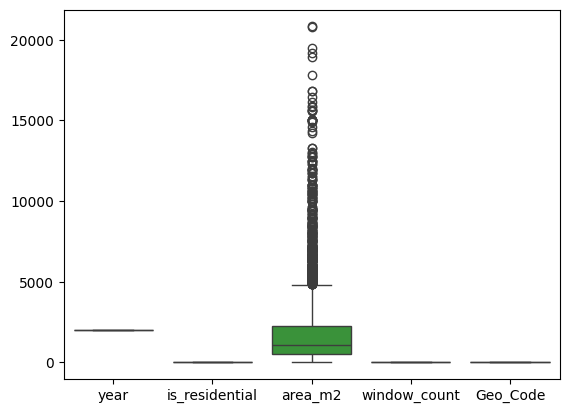

In [ ]:
# Boxplot des variables numériques du train pour repérer les outliers
sns.boxplot(data=train[l_num])
# Afficher la figure
plt.show()


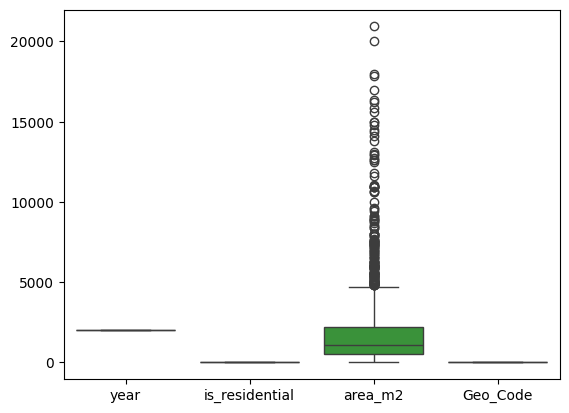

In [ ]:
# Boxplot des variables numériques du test pour repérer les outliers
sns.boxplot(data=test[l_num])
# Afficher la figure
plt.show()


In [ ]:
# Statistiques descriptives complètes du jeu d'entraînement
train.describe(include='all')


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
count,4974,4974.000000,4974,4974.000000,4974,4974,4974,4974.000000,4974,4974.000000,4974.000000,4974
unique,4974,NaN,2,NaN,4,2,2,NaN,4,NaN,NaN,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,NaN,NaN,non
freq,1,NaN,3676,NaN,2497,2503,2504,NaN,2310,NaN,NaN,3858
mean,NaN,2013.659630,NaN,0.303378,NaN,NaN,NaN,1857.265983,NaN,2.189988,4.515480,NaN
std,NaN,1.384232,NaN,0.459763,NaN,NaN,NaN,2252.842316,NaN,2.529276,2.868255,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,530.000000,NaN,0.000000,2.000000,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,1.000000,5.000000,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2247.750000,NaN,4.000000,7.000000,NaN


In [ ]:
# Fonction pour limiter les valeurs extrêmes de 'area_m2' via IQR

def boxplot_treatment(df):
  # Calcul des quartiles 25% et 75% de area_m2
  Q1, Q3 = np.percentile(df["area_m2"], [25, 75])
  # Intervalle interquartile
  IQR = Q3 - Q1
  # Seuil bas : max entre borne IQR et min+100 pour éviter valeurs trop petites
  lower_limit = max(Q1 - 1.5 * IQR, df["area_m2"].min() + 100)
  # Seuil haut classique IQR
  upper_limit = Q3 + 1.5 * IQR
  # Tronquer les valeurs supérieures au seuil haut
  df['area_m2'] = np.where(df['area_m2'] >= upper_limit,
  upper_limit, df['area_m2'])
  # Retourner le DataFrame ajusté
  return df
# Appliquer le traitement aux deux jeux
train = boxplot_treatment(train)
test = boxplot_treatment(test)


In [ ]:
# Statistiques descriptives après traitement des outliers (train)
train.describe(include='all')


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
count,4974,4974.000000,4974,4974.000000,4974,4974,4974,4974.000000,4974,4974.000000,4974.000000,4974
unique,4974,NaN,2,NaN,4,2,2,NaN,4,NaN,NaN,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,NaN,NaN,non
freq,1,NaN,3676,NaN,2497,2503,2504,NaN,2310,NaN,NaN,3858
mean,NaN,2013.659630,NaN,0.303378,NaN,NaN,NaN,1610.941848,NaN,2.189988,4.515480,NaN
std,NaN,1.384232,NaN,0.459763,NaN,NaN,NaN,1412.594381,NaN,2.529276,2.868255,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,530.000000,NaN,0.000000,2.000000,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,1.000000,5.000000,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2247.750000,NaN,4.000000,7.000000,NaN


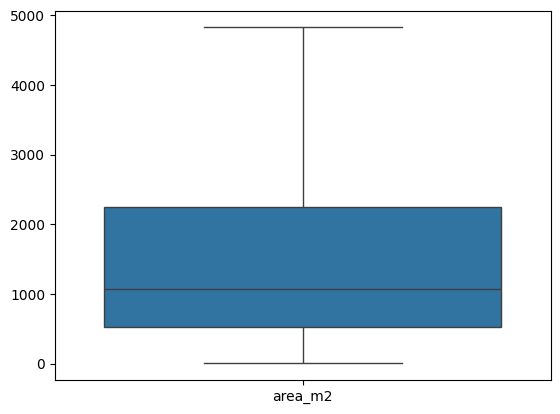

In [ ]:
# Boxplot de la variable area_m2 (train) pour visualiser la distribution
sns.boxplot(data=train[['area_m2']])
# Afficher la figure
plt.show()


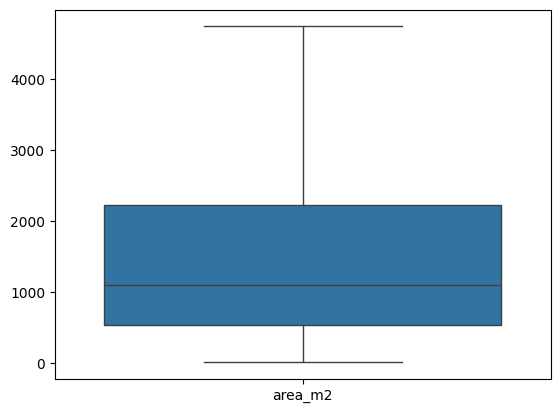

In [ ]:
# Boxplot de la variable area_m2 (test) pour visualiser la distribution
sns.boxplot(data=test[['area_m2']])
# Afficher la figure
plt.show()


In [ ]:
# Séparer la colonne combinée is_finished_and_fenced en deux colonnes
train[['is_finished', 'is_fenced']] = train['is_finished_and_fenced'].str.split('/', expand=True)
# Supprimer la colonne d'origine devenue redondante
train = train.drop('is_finished_and_fenced', axis=1)
# Mapper les valeurs 'N'/'V' en 0/1 pour is_finished
train['is_finished'] = train['is_finished'].map({'N': 0, 'V': 1})
# Mapper les valeurs 'N'/'V' en 0/1 pour is_fenced
train['is_fenced']   = train['is_fenced'].map({'N': 0, 'V': 1})
# Aperçu du DataFrame transformé
train.head()


,policy_id,year,coverage_period,is_residential,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim,is_finished,is_fenced
2,H13501,2012.0,1,1.0,V,U,1240.000,Wood-framed,0.0,7.0,non,0,1
3,H14962,2012.0,1,0.0,V,U,900.000,Non-combustible,0.0,5.0,non,0,1
4,H17755,2013.0,1,1.0,O,R,4824.375,Non-combustible,4.0,3.0,oui,1,0
5,H13369,2016.0,"0,5",0.0,V,U,600.000,Wood-framed,0.0,0.0,oui,0,1
6,H12988,2012.0,1,0.0,V,U,900.000,Non-combustible,0.0,5.0,non,0,1


In [ ]:
# Séparer la colonne combinée is_finished_and_fenced en deux colonnes (test)
test[['is_finished', 'is_fenced']] = test['is_finished_and_fenced'].str.split('/', expand=True)
# Supprimer la colonne d'origine devenue redondante
test = test.drop('is_finished_and_fenced', axis=1)
# Mapper les valeurs 'N'/'V' en 0/1 pour is_finished
test['is_finished'] = test['is_finished'].map({'N': 0, 'V': 1})
# Mapper les valeurs 'N'/'V' en 0/1 pour is_fenced
test['is_fenced']   = test['is_fenced'].map({'N': 0, 'V': 1})
# Aperçu du DataFrame transformé
test.head()


,policy_id,year,coverage_period,is_residential,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim,is_finished,is_fenced
0,H3733,2013,1,0,V,U,3760.0,Fire-resistive,0,4.0,oui,1,1
1,H16909,2015,1,0,O,R,1452.0,Fire-resistive,5,5.0,non,1,0
2,H16867,2013,1,1,O,R,1944.0,Ordinary,6,9.0,oui,1,0
3,H14813,2015,1,0,V,U,2270.0,Non-combustible,0,2.0,oui,0,1
4,H3728,2016,"0,5",0,O,R,2976.0,Fire-resistive,9,0.0,non,1,0


In [ ]:
# Encodage ordinal de 'is_residential'
enc = OrdinalEncoder()
train[["is_residential"]] = enc.fit_transform(
train.loc[:, ["is_residential"]])


# Encodage ordinal de 'claim'
enc = OrdinalEncoder()
train[["claim"]] = enc.fit_transform(
train.loc[:, ["claim"]])

# Encodage ordinal de 'locality'
enc = OrdinalEncoder()
train[["locality"]] = enc.fit_transform(
train.loc[:, ["locality"]])

# Encodage ordinal de 'has_garden'
enc = OrdinalEncoder()
train[["has_garden"]] = enc.fit_transform(
train.loc[:, ["has_garden"]])

# One-hot encoding sur 'structure_type' (sans préfixe)
train = pd.get_dummies(train, columns=['structure_type'], dtype='int32', prefix='', prefix_sep='')
# Déplacer la cible 'claim' en fin de DataFrame
claim_column = train.pop('claim')
train = pd.concat([train, claim_column], axis=1)

# Supprimer l'identifiant de police
train = train.drop('policy_id', axis=1)
# Afficher le DataFrame résultant
train


,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,is_finished,is_fenced,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
2,2012.0,1,1.0,1.0,1.0,1240.000,0.0,7.0,0,1,0,0,0,1,0.0
3,2012.0,1,0.0,1.0,1.0,900.000,0.0,5.0,0,1,0,1,0,0,0.0
4,2013.0,1,1.0,0.0,0.0,4824.375,4.0,3.0,1,0,0,1,0,0,1.0
5,2016.0,"0,5",0.0,1.0,1.0,600.000,0.0,0.0,0,1,0,0,0,1,1.0
6,2012.0,1,0.0,1.0,1.0,900.000,0.0,5.0,0,1,0,1,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5009,2013.0,1,0.0,1.0,1.0,550.000,0.0,3.0,0,1,0,0,1,0,1.0
5010,2012.0,"0,5",0.0,0.0,0.0,1000.000,4.0,1.0,1,0,1,0,0,0,0.0
5011,2015.0,1,1.0,0.0,0.0,480.000,3.0,9.0,1,0,0,0,1,0,0.0
5012,2012.0,"0,5",0.0,0.0,0.0,536.000,4.0,7.0,1,0,1,0,0,0,0.0


In [ ]:
# Encodage ordinal de 'is_residential' (test)
enc = OrdinalEncoder()
test[["is_residential"]] = enc.fit_transform(
    test.loc[:, ["is_residential"]]
)

# Encodage ordinal de 'claim' (test)
enc = OrdinalEncoder()
test[["claim"]] = enc.fit_transform(
    test.loc[:, ["claim"]]
)

# Encodage ordinal de 'locality' (test)
enc = OrdinalEncoder()
test[["locality"]] = enc.fit_transform(
    test.loc[:, ["locality"]]
)

# Encodage ordinal de 'has_garden' (test)
enc = OrdinalEncoder()
test[["has_garden"]] = enc.fit_transform(
test.loc[:, ["has_garden"]])


# One-hot encoding sur 'structure_type' (test)
test = pd.get_dummies(test, columns=['structure_type'], dtype='int32', prefix='', prefix_sep='')

# Déplacer la cible 'claim' en fin de DataFrame
claim_column = test.pop('claim')
test = pd.concat([test, claim_column], axis=1)

# Supprimer l'identifiant de police
test = test.drop('policy_id', axis=1)
# Afficher le DataFrame résultant
test


,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,is_finished,is_fenced,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,2013,1,0.0,1.0,1.0,3760.0,0,4.0,1,1,1,0,0,0,1.0
1,2015,1,0.0,0.0,0.0,1452.0,5,5.0,1,0,1,0,0,0,0.0
2,2013,1,1.0,0.0,0.0,1944.0,6,9.0,1,0,0,0,1,0,1.0
3,2015,1,0.0,1.0,1.0,2270.0,0,2.0,0,1,0,1,0,0,1.0
4,2016,"0,5",0.0,0.0,0.0,2976.0,9,0.0,1,0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,"0,5",1.0,0.0,0.0,862.0,2,0.0,1,0,0,0,0,1,0.0
2143,2012,1,0.0,1.0,1.0,1100.0,0,0.0,1,1,0,1,0,0,0.0
2144,2014,1,0.0,0.0,0.0,730.0,3,6.0,1,0,0,1,0,0,0.0
2145,2014,1,1.0,1.0,1.0,568.0,0,6.0,0,1,0,1,0,0,1.0


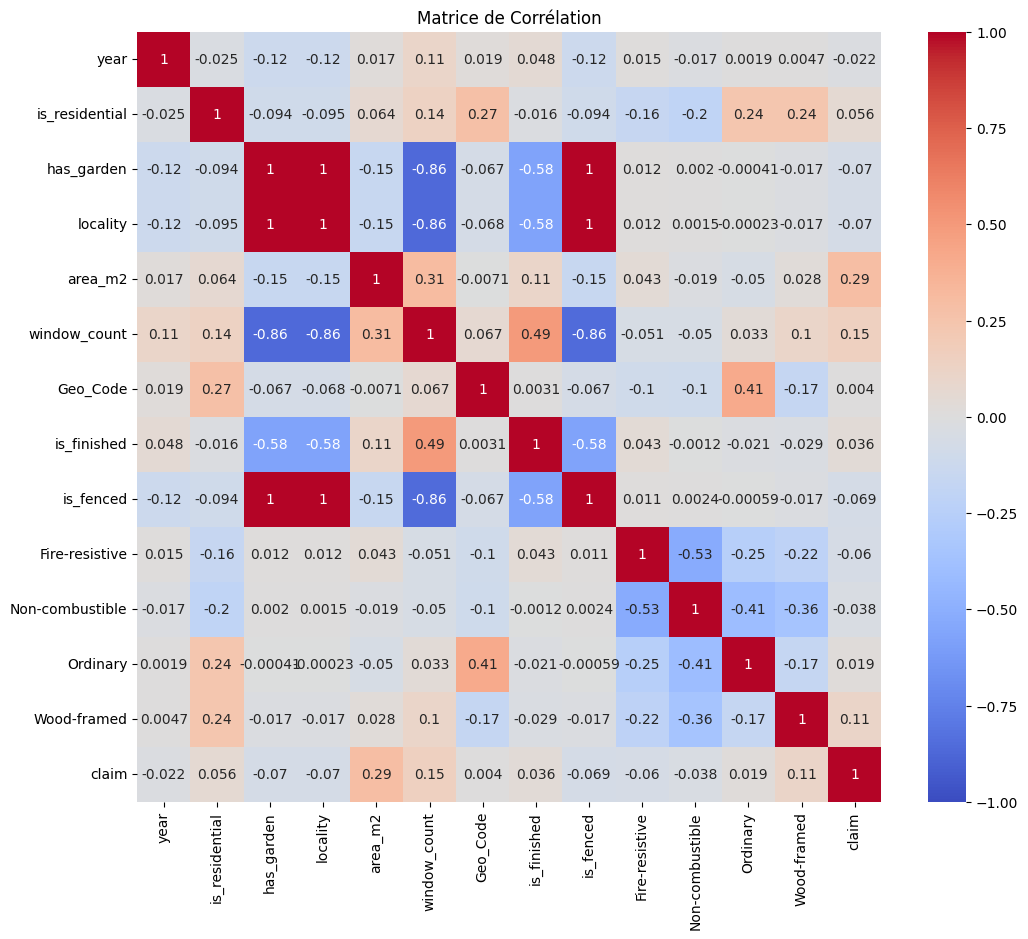

In [ ]:
# Calcul de la matrice de corrélation (train)
df_train = train.corr(numeric_only=True)
# Taille de la figure pour le heatmap
plt.figure(figsize=(12, 10))
# Heatmap des corrélations
sns.heatmap(df_train, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
# Titre du graphique
plt.title('Matrice de Corrélation')
# Afficher la figure
plt.show()


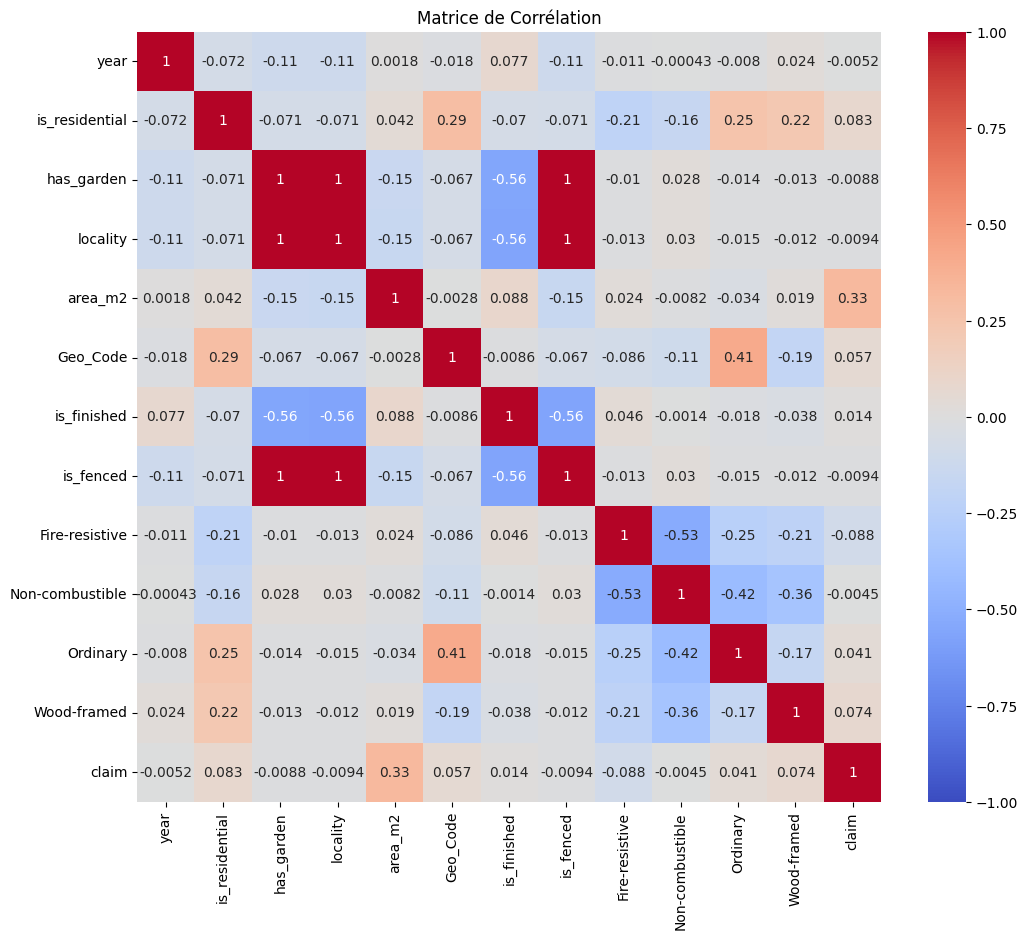

In [ ]:
# Calcul de la matrice de corrélation (test)
df_test = test.corr(numeric_only=True)
# Taille de la figure pour le heatmap
plt.figure(figsize=(12, 10))
# Heatmap des corrélations
sns.heatmap(df_test, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
# Titre du graphique
plt.title('Matrice de Corrélation')
# Afficher la figure
plt.show()



X = train.drop('claim', axis=1)
y = train['claim']


categorical_cols = X.select_dtypes(include=['object']).columns


X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)


if y.dtype == 'object':
    le = LabelEncoder()
    y = le.fit_transform(y)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestClassifier()
rf.fit(X_train, y_train)


importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Affichage complet
print(importances)


plt.figure(figsize=(12, 8))
sns.barplot(x="Importance", y="Feature", data=importances.head(20), palette="viridis")
plt.title("Top 20 Feature Importances (RandomForest)")
plt.show()


accuracy = rf.score(X_test, y_test)
print(f"Accuracy sur le test set : {accuracy:.4f}")


In [ ]:
# Supprimer des colonnes non nécessaires du train
train = train.drop('year', axis=1)                                                             
                                                             
train = train.drop('is_finished', axis=1)
train = train.drop('is_fenced', axis=1)
train = train.drop('has_garden', axis=1)
train = train.drop('locality', axis=1)
# Afficher le DataFrame résultant
train


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
2,1,1.0,1240.000,0.0,7.0,0,0,0,1,0.0
3,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
4,1,1.0,4824.375,4.0,3.0,0,1,0,0,1.0
5,"0,5",0.0,600.000,0.0,0.0,0,0,0,1,1.0
6,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
5009,1,0.0,550.000,0.0,3.0,0,0,1,0,1.0
5010,"0,5",0.0,1000.000,4.0,1.0,1,0,0,0,0.0
5011,1,1.0,480.000,3.0,9.0,0,0,1,0,0.0
5012,"0,5",0.0,536.000,4.0,7.0,1,0,0,0,0.0


In [ ]:
# Supprimer des colonnes non nécessaires du test
test = test.drop('year', axis=1)          

test = test.drop('is_finished', axis=1)
test = test.drop('is_fenced', axis=1)
test = test.drop('has_garden', axis=1)
test = test.drop('locality', axis=1)
# Afficher le DataFrame résultant
test


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,0.0,3760.0,0,4.0,1,0,0,0,1.0
1,1,0.0,1452.0,5,5.0,1,0,0,0,0.0
2,1,1.0,1944.0,6,9.0,0,0,1,0,1.0
3,1,0.0,2270.0,0,2.0,0,1,0,0,1.0
4,"0,5",0.0,2976.0,9,0.0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
2142,"0,5",1.0,862.0,2,0.0,0,0,0,1,0.0
2143,1,0.0,1100.0,0,0.0,0,1,0,0,0.0
2144,1,0.0,730.0,3,6.0,0,1,0,0,0.0
2145,1,1.0,568.0,0,6.0,0,1,0,0,1.0


In [ ]:
# Repérer les doublons dans le DataFrame train
train1 = train[train.duplicated()]
# Afficher les lignes dupliquées
train1


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
6,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
27,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
69,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
161,"0,5",0.0,4824.375,5.0,5.0,0,1,0,0,1.0
170,1,0.0,4824.375,0.0,6.0,0,1,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...
4984,"0,5",0.0,4824.375,0.0,2.0,0,1,0,0,0.0
4996,1,0.0,4142.000,10.0,4.0,0,1,0,0,0.0
5005,1,1.0,1176.000,0.0,9.0,0,0,1,0,1.0
5007,"0,5",0.0,300.000,0.0,2.0,0,1,0,0,0.0


In [ ]:
# Supprimer les doublons du DataFrame train en réindexant
train.drop_duplicates(inplace=True, ignore_index=True)
# Afficher le DataFrame après suppression
train


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,1.0,1240.000,0.0,7.0,0,0,0,1,0.0
1,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
2,1,1.0,4824.375,4.0,3.0,0,1,0,0,1.0
3,"0,5",0.0,600.000,0.0,0.0,0,0,0,1,1.0
4,"0,5",0.0,2675.000,0.0,4.0,0,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...
4293,"0,5",0.0,173.000,0.0,2.0,0,1,0,0,0.0
4294,1,0.0,550.000,0.0,3.0,0,0,1,0,1.0
4295,"0,5",0.0,1000.000,4.0,1.0,1,0,0,0,0.0
4296,"0,5",0.0,536.000,4.0,7.0,1,0,0,0,0.0


In [ ]:
# Vérifier à nouveau les doublons dans train
train1 = train[train.duplicated()]
# Afficher les doublons restants (si aucun, DataFrame vide)
train1


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim


In [ ]:
# Repérer les doublons dans le DataFrame test
test1 = test[test.duplicated()]
# Afficher les lignes dupliquées
test1


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
136,1,0.0,4740.0,4,7.0,0,1,0,0,1.0
413,1,1.0,520.0,0,3.0,1,0,0,0,0.0
431,1,0.0,1100.0,0,0.0,1,0,0,0,0.0
435,1,1.0,850.0,4,9.0,0,0,1,0,0.0
439,1,0.0,1100.0,0,0.0,0,1,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...
2116,1,0.0,1500.0,0,6.0,0,1,0,0,0.0
2122,1,0.0,460.0,0,4.0,0,1,0,0,0.0
2125,1,0.0,1325.0,0,4.0,0,0,1,0,0.0
2135,1,0.0,600.0,0,1.0,0,1,0,0,0.0


In [ ]:
# Supprimer les doublons du DataFrame test en réindexant
test.drop_duplicates(inplace=True, ignore_index=True)
# Afficher le DataFrame après suppression
test


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,0.0,3760.0,0,4.0,1,0,0,0,1.0
1,1,0.0,1452.0,5,5.0,1,0,0,0,0.0
2,1,1.0,1944.0,6,9.0,0,0,1,0,1.0
3,1,0.0,2270.0,0,2.0,0,1,0,0,1.0
4,"0,5",0.0,2976.0,9,0.0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
1975,"0,5",0.0,400.0,4,2.0,1,0,0,0,0.0
1976,"0,5",1.0,862.0,2,0.0,0,0,0,1,0.0
1977,1,0.0,730.0,3,6.0,0,1,0,0,0.0
1978,1,1.0,568.0,0,6.0,0,1,0,0,1.0


In [ ]:
# Vérifier à nouveau les doublons dans test
test1 = test[test.duplicated()]
# Afficher les doublons restants (si aucun, DataFrame vide)
test1


,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim


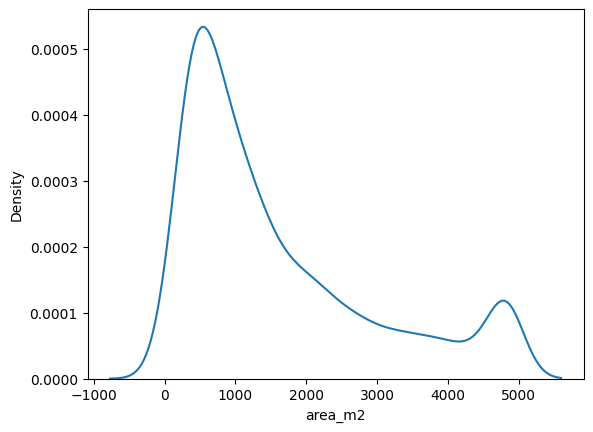

In [ ]:
# Densité (KDE) de area_m2 pour le train
sns.kdeplot(train['area_m2'], bw_method='scott', bw_adjust=1)
# Afficher la courbe
plt.show()


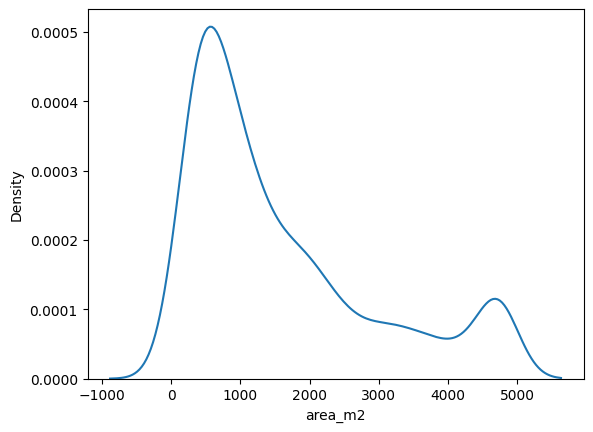

In [ ]:
# Densité (KDE) de area_m2 pour le test
sns.kdeplot(test['area_m2'], bw_method='scott', bw_adjust=1)
# Afficher la courbe
plt.show()


In [ ]:
# Cellule laissée vide intentionnellement (aucune instruction)


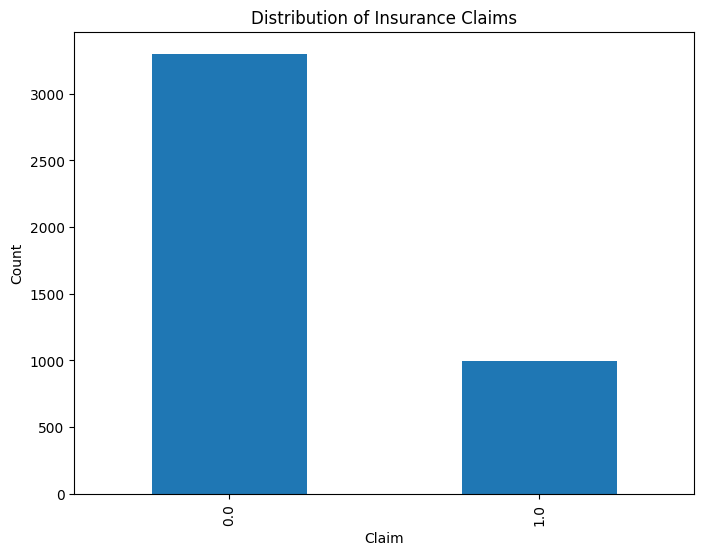

In [ ]:
# Diagramme en barres de la distribution de la variable cible 'claim'
plt.figure(figsize=(8, 6))
train['claim'].value_counts().plot(kind='bar')
plt.title('Distribution of Insurance Claims')
plt.xlabel('Claim')
plt.ylabel('Count')
plt.show()


In [ ]:
# Convertir 'coverage_period' en float en remplaçant la virgule par un point
train['coverage_period'] = train['coverage_period'].astype(str).str.replace(',', '.').astype('float64')
# Même conversion pour le jeu de test
test['coverage_period'] = test['coverage_period'].astype(str).str.replace(',', '.').astype('float64')


Après rééquilibrage : claim
0.0    3047
1.0    3047
Name: count, dtype: int64


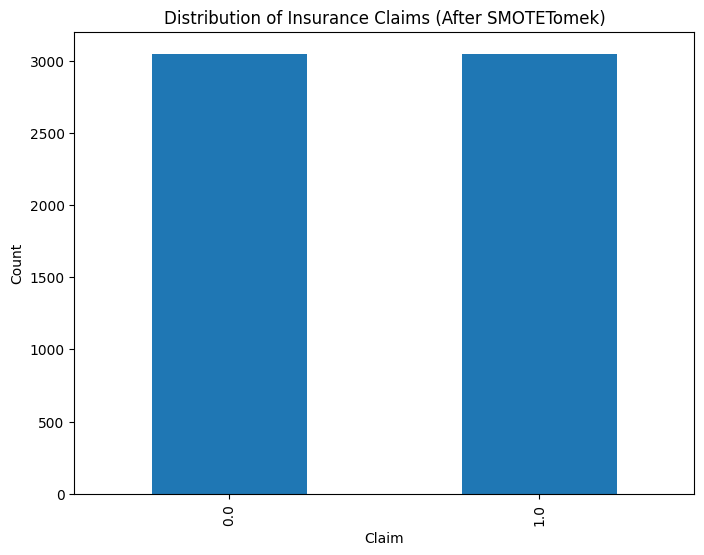

X_train shape: (4875, 9)
X_val shape: (1219, 9)
Distribution Y_train:
 claim
1.0    2438
0.0    2437
Name: count, dtype: int64
Distribution Y_val:
 claim
0.0    610
1.0    609
Name: count, dtype: int64


In [ ]:
# Imports pour rééquilibrage et prétraitement
from imblearn.combine import SMOTETomek
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# Séparer features et cible
X = train.drop('claim', axis=1)
y = train['claim']

# Appliquer SMOTETomek pour équilibrer les classes
smote_tomek = SMOTETomek(random_state=42)
X_resampled, y_resampled = smote_tomek.fit_resample(X, y)

# Afficher la répartition après rééquilibrage
print("Après rééquilibrage :", pd.Series(y_resampled).value_counts())

# Visualiser la distribution rééquilibrée
plt.figure(figsize=(8, 6))
pd.Series(y_resampled).value_counts().plot(kind='bar')
plt.title('Distribution of Insurance Claims (After SMOTETomek)')
plt.xlabel('Claim')
plt.ylabel('Count')
plt.show()

# Standardiser les variables
scaler = StandardScaler()
X_rescaled = scaler.fit_transform(X_resampled)

# Séparer entraînement/validation avec stratification
X_train, X_val, Y_train, Y_val = train_test_split(
    X_rescaled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled
)

# Afficher les dimensions et répartitions
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("Distribution Y_train:n", pd.Series(Y_train).value_counts())
print("Distribution Y_val:n", pd.Series(Y_val).value_counts())


In [ ]:
# Convertir 'window_count' en numérique float (train)
train['window_count'] = pd.to_numeric(train['window_count']).astype('float64')
# Convertir 'window_count' en numérique float (test)
test['window_count']  = pd.to_numeric(test['window_count']).astype('float64')


# Extraire X (features) et Y (cible) pour le train
X_train = train.iloc[:, :-1].values
Y_train = train.iloc[:, -1].values

# Extraire X (features) et Y (cible) pour le test
X_test  = test.iloc[:, :-1].values
Y_test  = test.iloc[:, -1].values


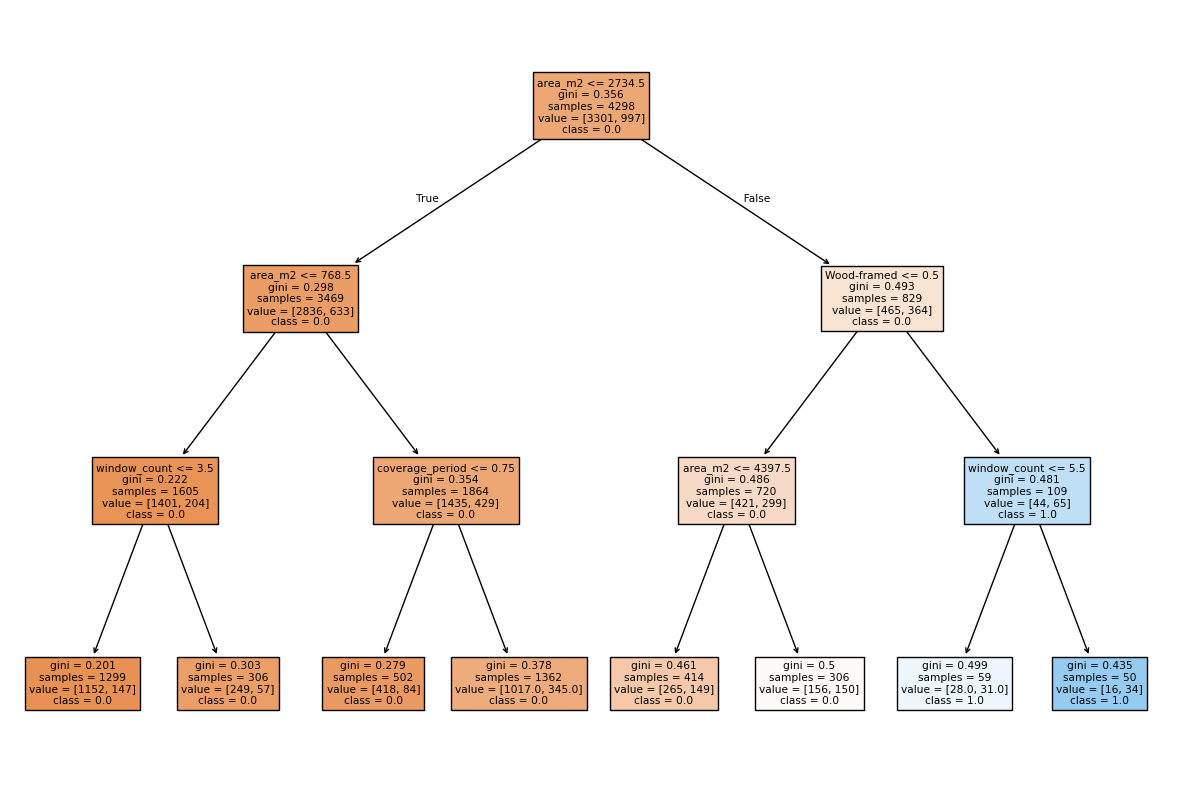

|--- area_m2 <= 2734.50
|   |--- area_m2 <= 768.50
|   |   |--- window_count <= 3.50
|   |   |   |--- class: 0.0
|   |   |--- window_count >  3.50
|   |   |   |--- class: 0.0
|   |--- area_m2 >  768.50
|   |   |--- coverage_period <= 0.75
|   |   |   |--- class: 0.0
|   |   |--- coverage_period >  0.75
|   |   |   |--- class: 0.0
|--- area_m2 >  2734.50
|   |--- Wood-framed <= 0.50
|   |   |--- area_m2 <= 4397.50
|   |   |   |--- class: 0.0
|   |   |--- area_m2 >  4397.50
|   |   |   |--- class: 0.0
|   |--- Wood-framed >  0.50
|   |   |--- window_count <= 5.50
|   |   |   |--- class: 1.0
|   |   |--- window_count >  5.50
|   |   |   |--- class: 1.0



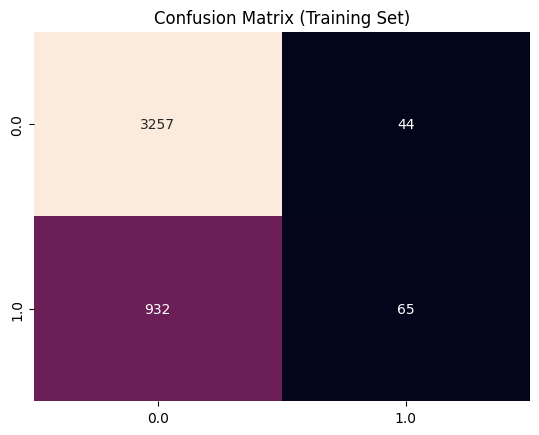

Accuracy on the training set: 77.29%


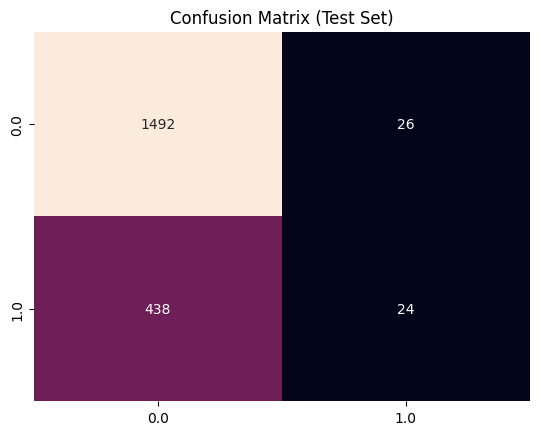

Accuracy on the test set: 76.57%
Training and testing completed.


In [ ]:
# Imports pour l'arbre de décision et les métriques
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt


# Initialiser et entraîner un arbre de décision de profondeur 3
cls = DecisionTreeClassifier(max_depth=3)
cls.fit(X_train, Y_train)

# Visualiser l'arbre entraîné
fig = plt.figure(figsize=(15, 10))
plot_tree(cls, feature_names=list(train)[:-1], class_names=[str(cls_class) for cls_class in cls.classes_], filled=True)
plt.show()

# Afficher la représentation textuelle de l'arbre
print(export_text(cls, feature_names=list(train)[:-1]))

# Prédictions sur le train
Y_p_train = cls.predict(X_train)
# Matrice de confusion train
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Accuracy sur le train
accuracy_train = accuracy_score(Y_train, Y_p_train)

# Heatmap de la matrice de confusion train
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=[str(cls_class) for cls_class in cls.classes_], yticklabels=[str(cls_class) for cls_class in cls.classes_], fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

# Afficher l'accuracy train
print(f"Accuracy on the training set: {accuracy_train:.2%}")

# Prédictions sur le test
Y_p_test = cls.predict(X_test)
# Matrice de confusion test
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Accuracy sur le test
accuracy_test = accuracy_score(Y_test, Y_p_test)

# Heatmap de la matrice de confusion test
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=[str(cls_class) for cls_class in cls.classes_], yticklabels=[str(cls_class) for cls_class in cls.classes_], fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

# Afficher l'accuracy test
print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


[0.77751253 0.59633028] [0.98667071 0.06519559] [0.86969292 0.11754069] [3301  997]


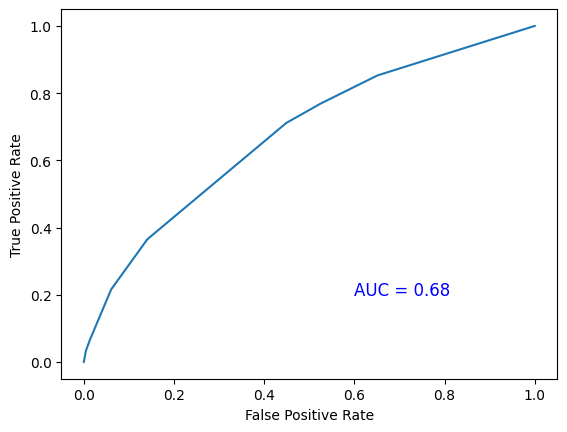

[0.77305699 0.48      ] [0.9828722  0.05194805] [0.86542923 0.09375   ] [1518  462]


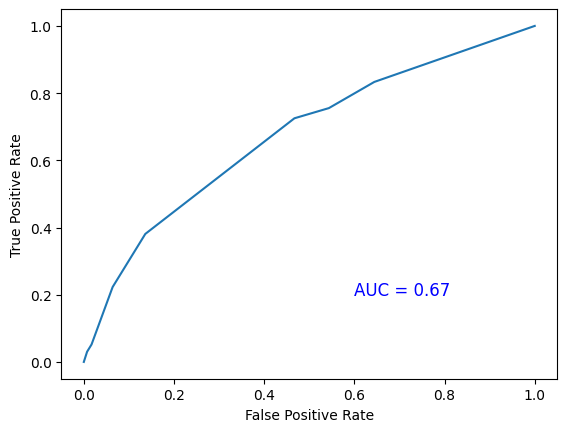

In [ ]:
# Imports métriques supplémentaires et courbes ROC
from sklearn.metrics import precision_recall_fscore_support, roc_curve, roc_auc_score
# Calcul métriques PRF1 sur le train
precision, recall, f1, occ = precision_recall_fscore_support(Y_train,
Y_p_train, average=None)
print(precision, recall, f1, occ)
# Probabilités prédites pour la classe positive (train)
y_train_prob = cls.predict_proba(X_train)[:, 1]
# Courbe ROC train
fpr, tpr, thresholds = roc_curve(Y_train, y_train_prob, pos_label=1)
auc = roc_auc_score(Y_train, y_train_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.text(0.6, 0.2, f'AUC = {auc:.2f}',
 color='blue', fontsize=12)
plt.show()
# Calcul métriques PRF1 sur le test
precision, recall, f1, occ = precision_recall_fscore_support(Y_test,
Y_p_test, average=None)
print(precision, recall, f1, occ)
# Probabilités prédites pour la classe positive (test)
y_test_prob = cls.predict_proba(X_test)[:, 1]
# Courbe ROC test
fpr, tpr, thresholds = roc_curve(Y_test, y_test_prob, pos_label=1)
auc = roc_auc_score(Y_test, y_test_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.text(0.6, 0.2, f'AUC = {auc:.2f}',
 color='blue', fontsize=12)
plt.show()


In [ ]:
# Complément du rappel (1 - recall) par classe
complement_recall = 1 - recall
print("Class-wise complement of recall:")
for i, class_label in enumerate(cls.classes_):
    print(f"Class {class_label}: {complement_recall[i]:.2%}")
# Complément de la précision (1 - precision) par classe
complement_precision = 1 - precision
print("Class-wise complement of precision:")
for i, class_label in enumerate(cls.classes_):
    print(f"Class {class_label}: {complement_precision[i]:.2%}")


Class-wise complement of recall:
Class 0.0: 1.71%
Class 1.0: 94.81%
Class-wise complement of precision:
Class 0.0: 22.69%
Class 1.0: 52.00%


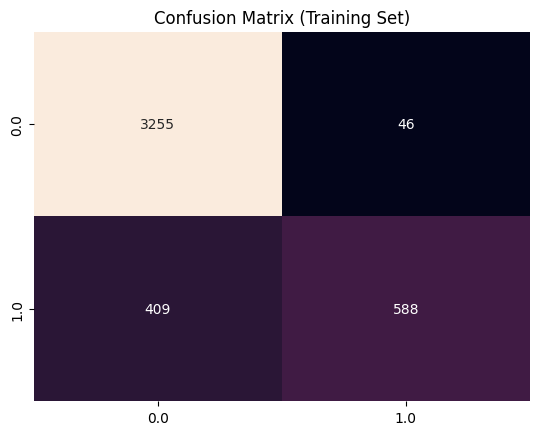

Accuracy on the training set: 89.41%


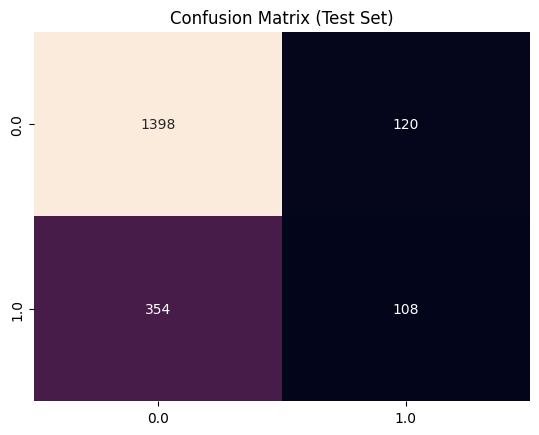

Accuracy on the test set: 76.06%
Training and testing completed.


In [ ]:
# Importer pandas pour manipuler les DataFrames
import pandas as pd
# Importer numpy pour les opérations numériques
import numpy as np
# Importer le classifieur RandomForest de scikit-learn
from sklearn.ensemble import RandomForestClassifier
# Importer les métriques de base pour évaluer le modèle
from sklearn.metrics import confusion_matrix, accuracy_score
# Importer seaborn pour les visualisations
import seaborn as sns
# Importer matplotlib pour afficher les figures
import matplotlib.pyplot as plt


# Configurer un RandomForest avec les hyperparamètres indiqués
cls = RandomForestClassifier(
    n_estimators=100,              
    criterion='gini',              
    max_depth=None,                
    min_samples_split=2,           
    min_samples_leaf=1,            
    max_features='sqrt',           
    max_leaf_nodes=None,           
    bootstrap=True,                
    oob_score=True,                
    max_samples=0.53               
)
# Entraîner le modèle sur l'échantillon d'apprentissage
cls.fit(X_train, Y_train)

# Générer les prédictions sur le train
Y_p_train = cls.predict(X_train)
# Calculer la matrice de confusion sur le train
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Calculer l'accuracy sur le train
accuracy_train = accuracy_score(Y_train, Y_p_train)

# Tracer la matrice de confusion pour le train
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

# Afficher l'accuracy train
print(f"Accuracy on the training set: {accuracy_train:.2%}")

# Générer les prédictions sur le test
Y_p_test = cls.predict(X_test)
# Calculer la matrice de confusion sur le test
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Calculer l'accuracy sur le test
accuracy_test = accuracy_score(Y_test, Y_p_test)

# Tracer la matrice de confusion pour le test
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

# Afficher l'accuracy test et un message de fin
print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


In [ ]:
# Importer RandomForest pour un modèle pondéré équilibré
from sklearn.ensemble import RandomForestClassifier

# Initialiser un RandomForest en équilibrant les classes via class_weight
cls = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    class_weight='balanced',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    max_leaf_nodes=None,
    bootstrap=True,
    oob_score=True,
    max_samples=0.53
)
# Entraîner le modèle sur le train
cls.fit(X_train, Y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


[[3212   89]
 [ 362  635]]


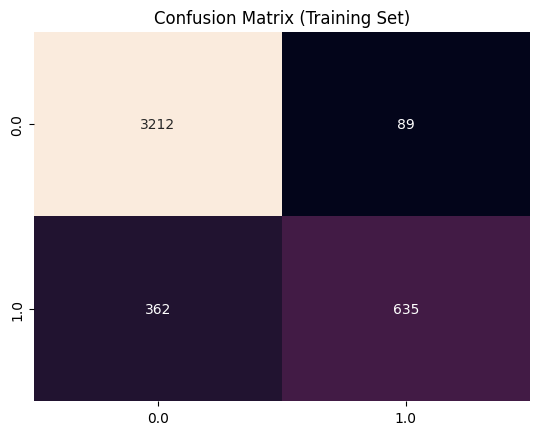

Accuracy on the test set: 76.06%
[[1385  133]
 [ 352  110]]


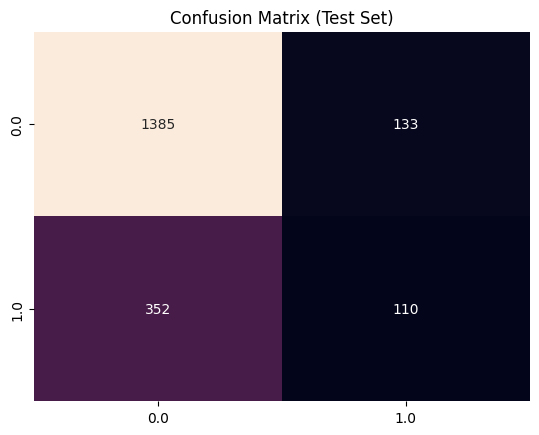

Accuracy on the test set: 75.51%
Training and testing completed.


In [ ]:
# Importer pandas pour compléter les analyses éventuelles
import pandas as pd
# Importer numpy pour les calculs numériques
import numpy as np
# Importer les métriques de confusion et d'accuracy
from sklearn.metrics import confusion_matrix, accuracy_score
# Importer seaborn pour les heatmaps
import seaborn as sns
# Importer matplotlib pour afficher les figures
import matplotlib.pyplot as plt


# Générer les prédictions sur le train
Y_p_train = cls.predict(X_train)
# Construire la matrice de confusion sur le train
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Calculer l'accuracy sur le train
accuracy_train = accuracy_score(Y_train, Y_p_train)
print(c_m_train)
# Visualiser la matrice de confusion train
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

# Afficher l'accuracy train
print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Générer les prédictions sur le test
Y_p_test = cls.predict(X_test)
# Construire la matrice de confusion sur le test
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Calculer l'accuracy sur le test
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(c_m_test)
# Visualiser la matrice de confusion test
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

# Afficher l'accuracy test et un message de fin
print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


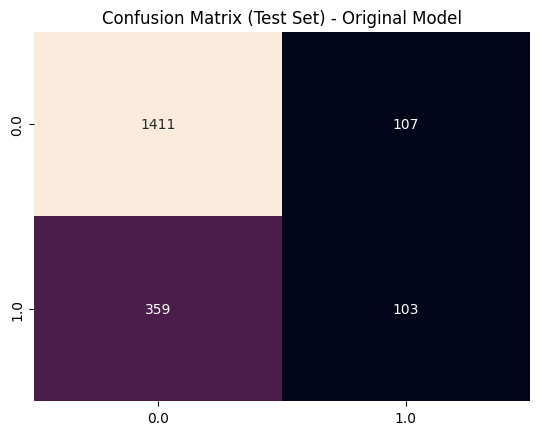

Accuracy on the test set: 76.46%


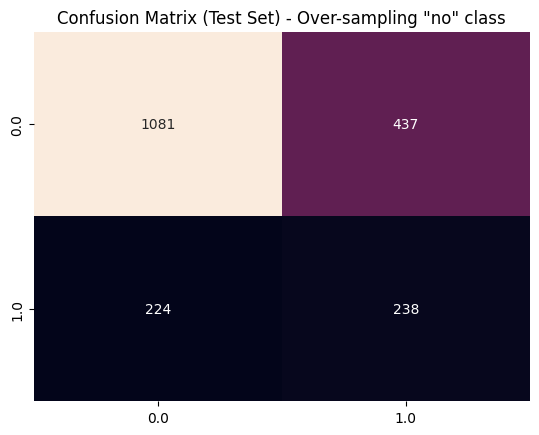

Accuracy on the test set (with over-sampling): 66.62%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.over_sampling import RandomOverSampler
import seaborn as sns
import matplotlib.pyplot as plt


cls = RandomForestClassifier(
    n_estimators=100,              
    criterion='gini',                
    max_depth=None,                               
    min_samples_split=2,                                       
    min_samples_leaf=1,                                     
    max_features='sqrt',                                       
    max_leaf_nodes=None,                             
    bootstrap=True,                    
    oob_score=True,                           
    max_samples=0.53                                  
)
cls.fit(X_train, Y_train)

Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Original Model')
plt.show()

accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

ros = RandomOverSampler(sampling_strategy={1.0: 6000})
X_train_resampled, Y_train_resampled = ros.fit_resample(X_train, Y_train)

cls.fit(X_train_resampled, Y_train_resampled)
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Over-sampling "no" class')
plt.show()

accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set (with over-sampling): {accuracy_test:.2%}")

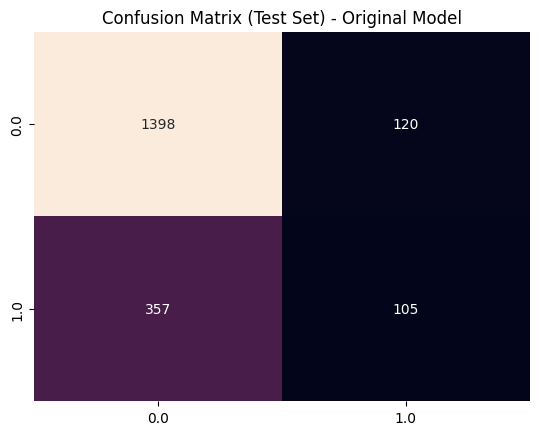

Accuracy on the test set: 75.91%


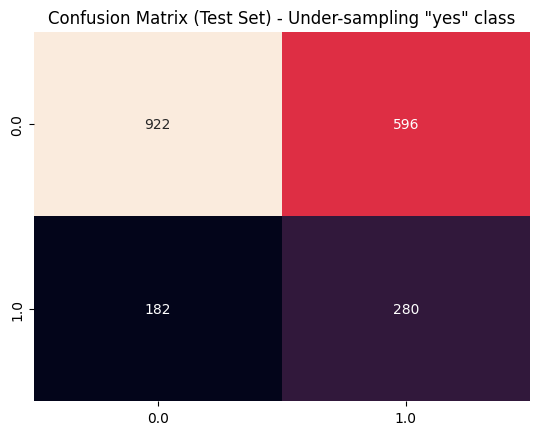

Accuracy on the test set (with under-sampling): 60.71%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
import seaborn as sns
import matplotlib.pyplot as plt


cls = RandomForestClassifier(
    n_estimators=100,              
    criterion='gini',                
    max_depth=None,                               
    min_samples_split=2,                                       
    min_samples_leaf=1,                                     
    max_features='sqrt',                                       
    max_leaf_nodes=None,                             
    bootstrap=True,                    
    oob_score=True,                    
    max_samples=0.53                                  
)
cls.fit(X_train, Y_train)

Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Original Model')
plt.show()

accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

rus = RandomUnderSampler(sampling_strategy={0.0: 1000})
X_train_resampled, Y_train_resampled = rus.fit_resample(X_train, Y_train)

cls.fit(X_train_resampled, Y_train_resampled)
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Under-sampling "yes" class')
plt.show()

accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set (with under-sampling): {accuracy_test:.2%}")

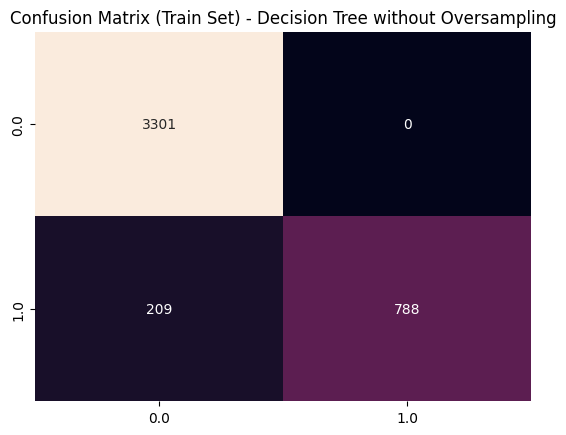

Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      1.00      0.97      3301
         1.0       1.00      0.79      0.88       997

    accuracy                           0.95      4298
   macro avg       0.97      0.90      0.93      4298
weighted avg       0.95      0.95      0.95      4298

Accuracy on the test set: 95.14%

Classification Report (Adjusted Threshold):
              precision    recall  f1-score   support

         0.0       1.00      0.94      0.97      3301
         1.0       0.83      1.00      0.91       997

    accuracy                           0.95      4298
   macro avg       0.91      0.97      0.94      4298
weighted avg       0.96      0.95      0.95      4298

Accuracy on the training set (Adjusted Threshold): 95.14%


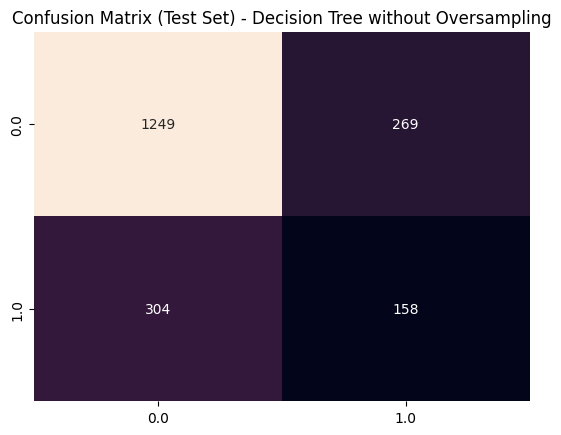

Classification Report:
              precision    recall  f1-score   support

         0.0       0.80      0.82      0.81      1518
         1.0       0.37      0.34      0.36       462

    accuracy                           0.71      1980
   macro avg       0.59      0.58      0.58      1980
weighted avg       0.70      0.71      0.71      1980

Accuracy on the test set: 71.06%

Classification Report (Adjusted Threshold):
              precision    recall  f1-score   support

         0.0       0.81      0.77      0.79      1518
         1.0       0.34      0.40      0.37       462

    accuracy                           0.68      1980
   macro avg       0.57      0.58      0.58      1980
weighted avg       0.70      0.68      0.69      1980

Accuracy on the test set (Adjusted Threshold): 68.08%


In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt


cls = DecisionTreeClassifier(criterion='entropy', random_state=42)
cls.fit(X_train, Y_train)

Y_p_train = cls.predict(X_train)
c_m_train = confusion_matrix(Y_train, Y_p_train)

sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Train Set) - Decision Tree without Oversampling')
plt.show()

print("Classification Report:")
print(classification_report(Y_train, Y_p_train))

accuracy_test = accuracy_score(Y_train, Y_p_train)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

threshold = 0.0005                                                      
Y_p_train_adjusted = (cls.predict_proba(X_train)[:, 1] > threshold).astype(int)

print("nClassification Report (Adjusted Threshold):")
print(classification_report(Y_train, Y_p_train_adjusted))

accuracy_train_adjusted = accuracy_score(Y_train, Y_p_train_adjusted)
print(f"Accuracy on the training set (Adjusted Threshold): {accuracy_train_adjusted:.2%}")

Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Decision Tree without Oversampling')
plt.show()

print("Classification Report:")
print(classification_report(Y_test, Y_p_test))

accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

threshold = 0.0005                
Y_p_test_adjusted = (cls.predict_proba(X_test)[:, 1] > threshold).astype(int)

print("nClassification Report (Adjusted Threshold):")
print(classification_report(Y_test, Y_p_test_adjusted))

accuracy_test_adjusted = accuracy_score(Y_test, Y_p_test_adjusted)
print(f"Accuracy on the test set (Adjusted Threshold): {accuracy_test_adjusted:.2%}")

=== Random Forest ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.95
F1-score (train) : 0.89
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.74
F1-score (test) : 0.34
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.80      0.87      0.84      1518
         1.0       0.41      0.29      0.34       462

    accuracy                           0.74      1980
   macro avg       0.61      0.58      0.59      1980
weighted avg       0.71      0.74      0.72      1980



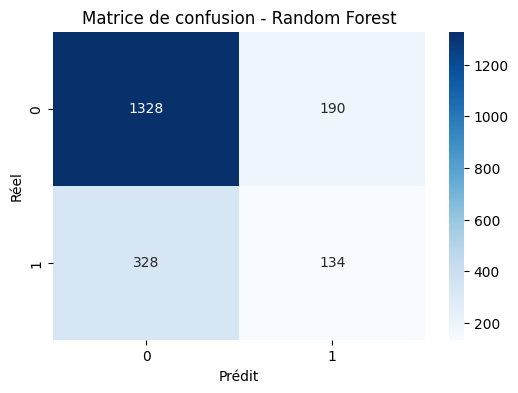

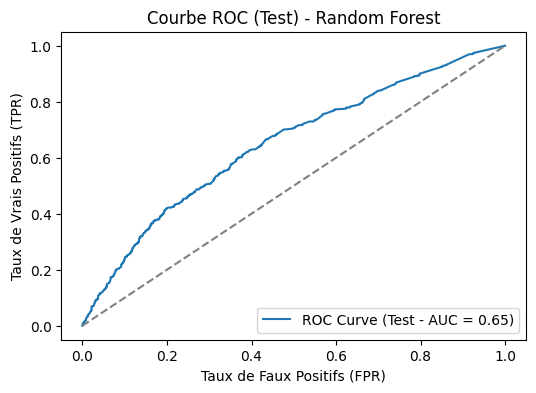

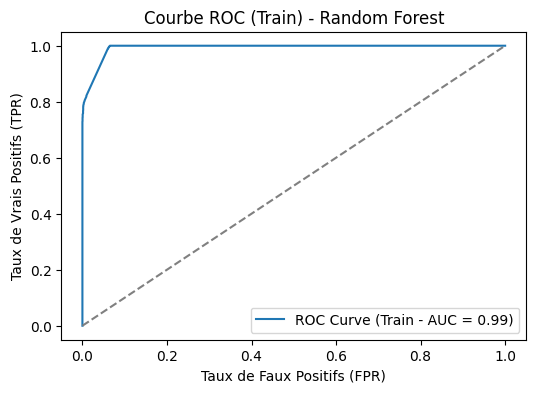

=== Gradient Boosting ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.79
F1-score (train) : 0.32
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.28
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.79      0.95      0.86      1518
         1.0       0.53      0.19      0.28       462

    accuracy                           0.77      1980
   macro avg       0.66      0.57      0.57      1980
weighted avg       0.73      0.77      0.73      1980



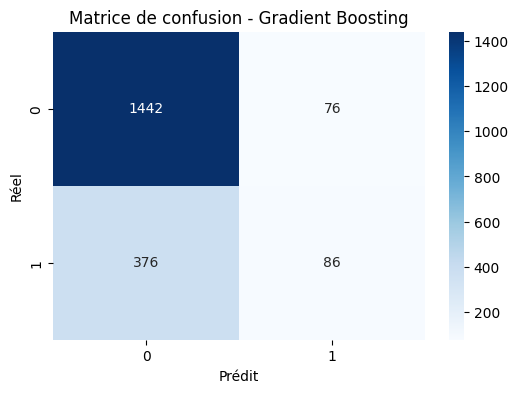

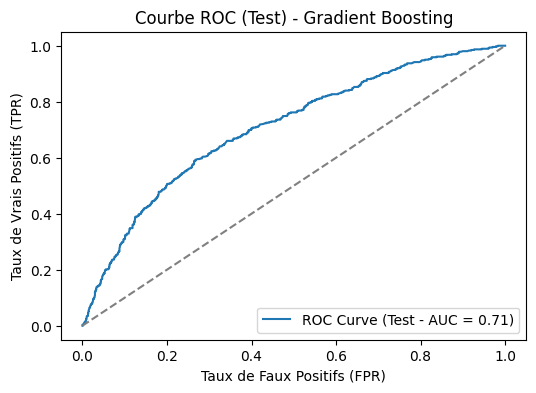

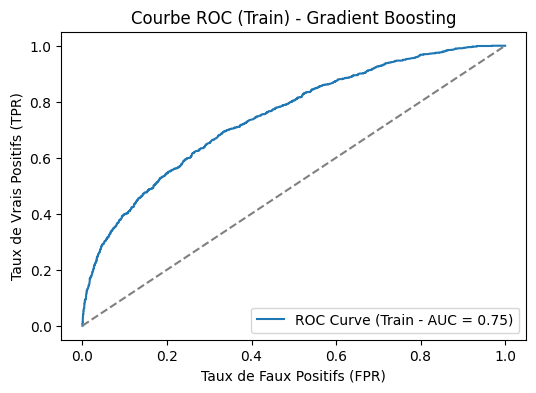

=== Logistic Regression ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.78
F1-score (train) : 0.23
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.19
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.78      0.97      0.86      1518
         1.0       0.52      0.12      0.19       462

    accuracy                           0.77      1980
   macro avg       0.65      0.54      0.53      1980
weighted avg       0.72      0.77      0.71      1980



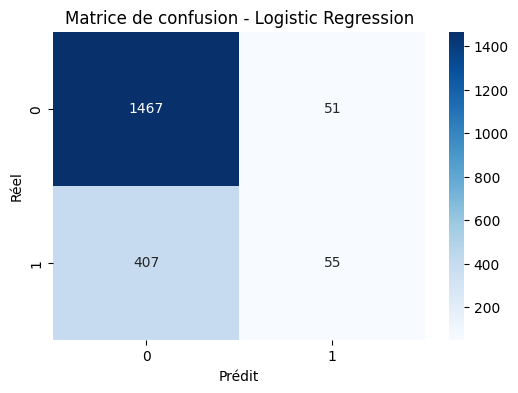

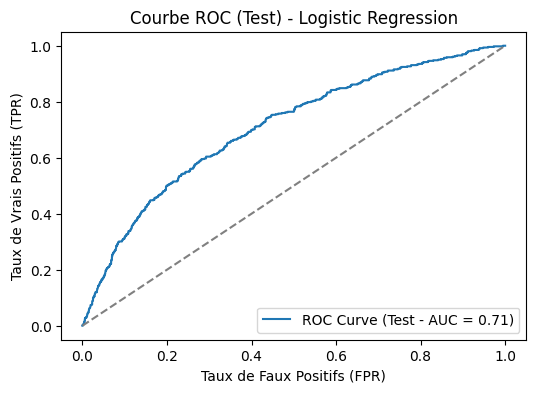

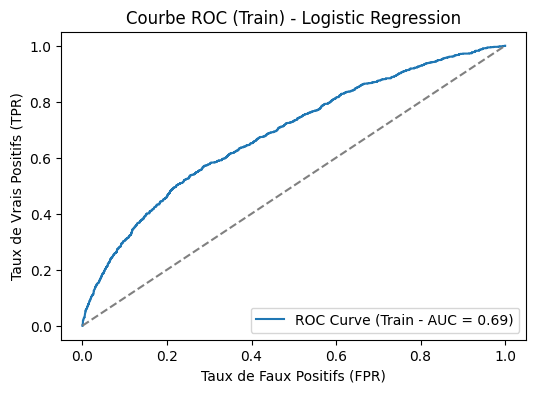

=== SVM ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.77
F1-score (train) : 0.00
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.00
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.77      1.00      0.87      1518
         1.0       0.00      0.00      0.00       462

    accuracy                           0.77      1980
   macro avg       0.38      0.50      0.43      1980
weighted avg       0.59      0.77      0.67      1980



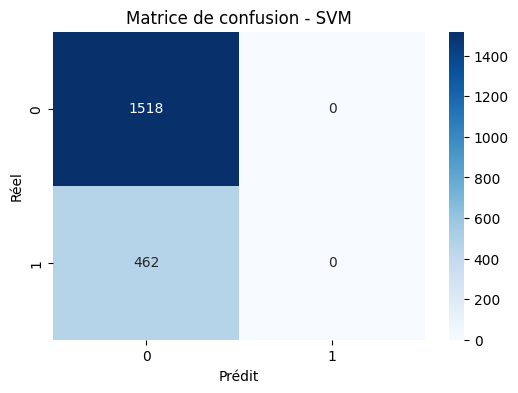

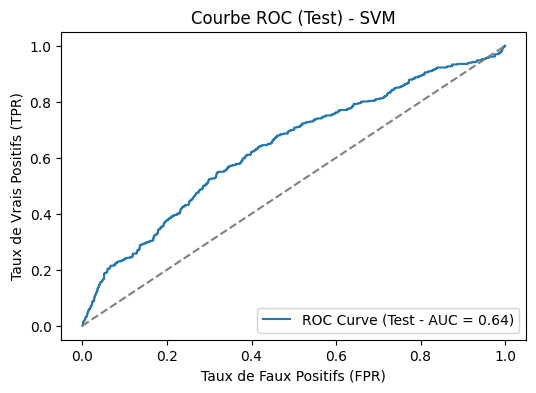

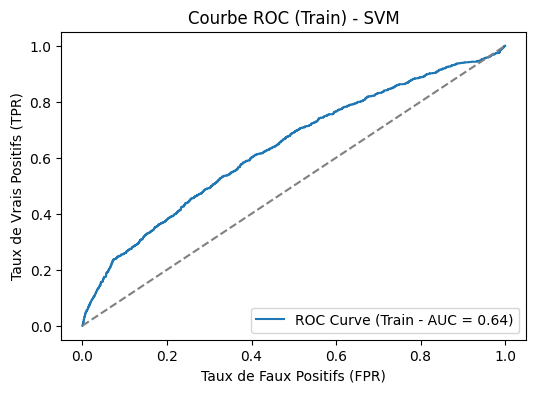

=== KNN ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.80
F1-score (train) : 0.42
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.74
F1-score (test) : 0.31
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.79      0.89      0.84      1518
         1.0       0.40      0.25      0.31       462

    accuracy                           0.74      1980
   macro avg       0.60      0.57      0.57      1980
weighted avg       0.70      0.74      0.71      1980



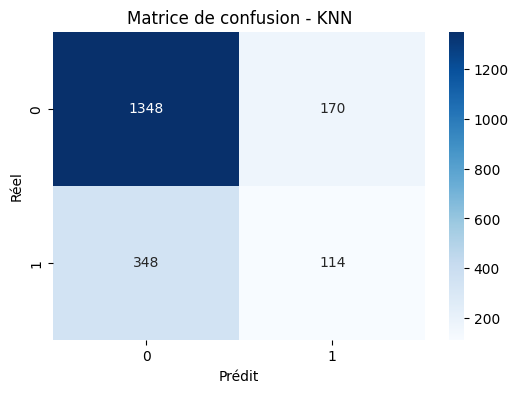

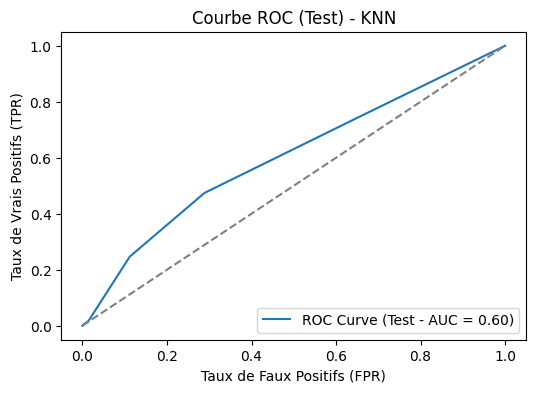

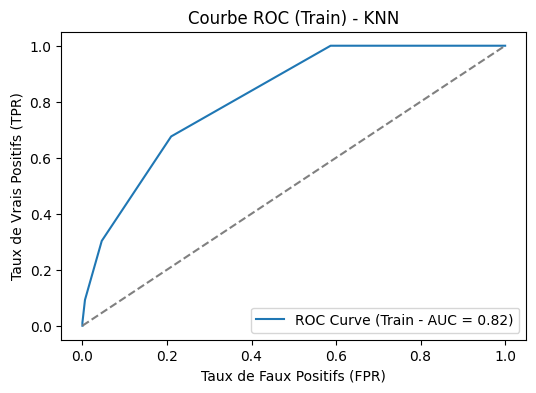

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Random Forest": RandomForestClassifier(),                                              
    "Gradient Boosting": GradientBoostingClassifier(),                                                
    "Logistic Regression": LogisticRegression(max_iter=1000),                                                  
    "SVM": SVC(probability=True),                                                       
    "KNN": KNeighborsClassifier()                                                  
}

for name, model in models.items():
    print(f"=== {name} ===")
    model.fit(X_train, Y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    y_train_prob = model.predict_proba(X_train)[:, 1] if hasattr(model, "predict_proba") else None
    y_test_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    print(f"--- Évaluation sur le jeu d'entraînement ---")
    print(f"Accuracy (train) : {accuracy_score(Y_train, y_train_pred):.2f}")
    print(f"F1-score (train) : {f1_score(Y_train, y_train_pred):.2f}")

    print(f"--- Évaluation sur le jeu de test ---")
    print(f"Accuracy (test) : {accuracy_score(Y_test, y_test_pred):.2f}")
    print(f"F1-score (test) : {f1_score(Y_test, y_test_pred):.2f}")
    print("Classification Report (test) :n", classification_report(Y_test, y_test_pred))

    cm = confusion_matrix(Y_test, y_test_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.show()

    if y_test_prob is not None:
        fpr_test, tpr_test, _ = roc_curve(Y_test, y_test_prob)
        auc_test = roc_auc_score(Y_test, y_test_prob)
        plt.figure(figsize=(6, 4))
        plt.plot(fpr_test, tpr_test, label=f"ROC Curve (Test - AUC = {auc_test:.2f})")
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.xlabel("Taux de Faux Positifs (FPR)")
        plt.ylabel("Taux de Vrais Positifs (TPR)")
        plt.title(f"Courbe ROC (Test) - {name}")
        plt.legend(loc="lower right")
        plt.show()

        fpr_train, tpr_train, _ = roc_curve(Y_train, y_train_prob)
        auc_train = roc_auc_score(Y_train, y_train_prob)
        plt.figure(figsize=(6, 4))
        plt.plot(fpr_train, tpr_train, label=f"ROC Curve (Train - AUC = {auc_train:.2f})")
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.xlabel("Taux de Faux Positifs (FPR)")
        plt.ylabel("Taux de Vrais Positifs (TPR)")
        plt.title(f"Courbe ROC (Train) - {name}")
        plt.legend(loc="lower right")
        plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt


svc_params = {
    'C': [0.1, 1, 10, 100],                                        
    'kernel': ['rbf', 'poly'],                                                       
    'gamma': ['scale', 0.1]                        
}
mlp_params = {
    'hidden_layer_sizes': [(50,), (100,)],                                               
    'activation': ['relu'],                                
    'alpha': [0.0001, 0.001],                                  
    'learning_rate': ['adaptive']                                  
}
gb_params = {
    'n_estimators': [100, 200],                                 
    'learning_rate': [0.05, 0.1],                        
    'max_depth': [3, 4],                                  
    'min_samples_split': [2, 5]                                                      
}

svc = RandomizedSearchCV(SVC(random_state=42), svc_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
svc.fit(X_train, Y_train)

mlp = RandomizedSearchCV(MLPClassifier(random_state=42, max_iter=300), mlp_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
mlp.fit(X_train, Y_train)

gb = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), gb_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
gb.fit(X_train, Y_train)

def evaluate_model(model, X_test, Y_test, model_name):
    Y_pred = model.predict(X_test)
    cm = confusion_matrix(Y_test, Y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
    
    print(f"Classification Report - {model_name}")
    print(classification_report(Y_test, Y_pred))
    print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")

evaluate_model(svc.best_estimator_, X_test, Y_test, "SVC")
evaluate_model(mlp.best_estimator_, X_test, Y_test, "MLP Classifier")
evaluate_model(gb.best_estimator_, X_test, Y_test, "Gradient Boosting")

print("Best parameters for SVC:", svc.best_params_)
print("Best parameters for MLP:", mlp.best_params_)
print("Best parameters for Gradient Boosting:", gb.best_params_)

KeyboardInterrupt: 

<Figure size 1200x600 with 0 Axes>

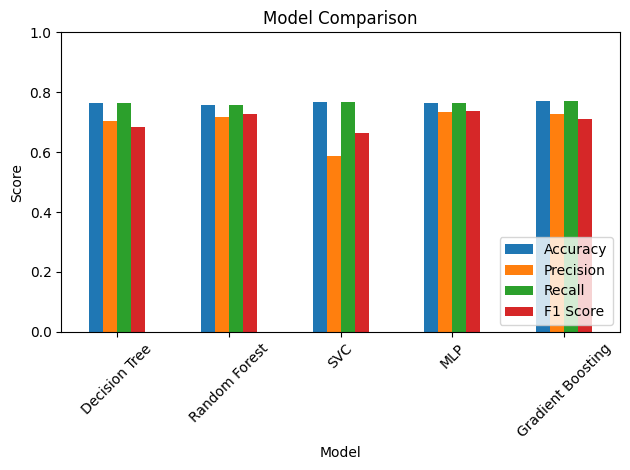

               Model  Accuracy  Precision    Recall  F1 Score
0      Decision Tree  0.765657   0.704677  0.765657  0.685371
1      Random Forest  0.756566   0.718172  0.756566  0.725980
2                SVC  0.766667   0.587778  0.766667  0.665409
3                MLP  0.764646   0.732662  0.764646  0.739064
4  Gradient Boosting  0.771212   0.727666  0.771212  0.710019


In [ ]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import matplotlib.pyplot as plt

models = [
    ("Decision Tree", DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, class_weight='balanced', max_samples=0.53, random_state=42)),
    ("SVC", svc.best_estimator_),
    ("MLP", mlp.best_estimator_),
    ("Gradient Boosting", gb.best_estimator_)
]

results = []
for name, model in models:
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(Y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(Y_test, y_pred, average='weighted')
    results.append((name, accuracy, precision, recall, f1))

df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

print("n" + "=" * 90)
print("📊 COMPARAISON FINALE DE TOUS LES MODÈLES DE MACHINE LEARNING")
print("=" * 90)
print("n✅ ÉTAPE 1 : RÉSUMÉ DE L'EXPÉRIENCE")
print("-" * 90)
print("✓ 5 modèles différents ont été créés et entraînés")
print("✓ Tous les modèles ont été testés sur LES MÊMES données (ensemble de test)")
print("✓ 4 métriques importantes ont été calculées pour chaque modèle")
print("✓ Cela nous permet de comparer objectivement lequel fonctionne le mieuxn")

print("✅ ÉTAPE 2 : VISUALISATION GRAPHIQUE DES RÉSULTATS")
print("-" * 90)
print("Voici un graphique qui montre visuellement les performances de chaque modèle:n")

plt.figure(figsize=(12, 6))
df_results.set_index('Model').plot(kind='bar', ylim=[0, 1])
plt.title('📈 Comparaison des Performances des Modèles', fontsize=14, fontweight='bold')
plt.ylabel('Score (0 à 1 = 0% à 100%)', fontsize=11)
plt.xlabel('Modèles', fontsize=11)
plt.xticks(rotation=45)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

print("n✅ ÉTAPE 3 : TABLEAU DES RÉSULTATS DÉTAILLÉS")
print("=" * 90)
print("n📋 Voici le tableau complet avec tous les scores de chaque modèle:n")
print(df_results.to_string(index=False))

print("nn✅ ÉTAPE 4 : EXPLICATION DES MÉTRIQUES")
print("=" * 90)
print("""
🔹 ACCURACY (Exactitude) :
   → Pourcentage de prédictions correctes
   → Plus la valeur est proche de 100%, mieux c'est
   → C'est la métrique la plus importante pour notre problème

🔹 PRECISION (Précision) :
   → Sur les personnes prédites comme "réclamant", quel % a vraiment réclamé ?
   → Évite les faux positifs (dire "oui" quand c'est "non")

🔹 RECALL (Sensibilité) :
   → Sur les personnes qui ont VRAIMENT réclamé, quel % a été détecté ?
   → Évite les faux négatifs (dire "non" quand c'est "oui")

🔹 F1-SCORE :
   → C'est un équilibre entre Precision et Recall
   → Utile quand on veut un bon équilibre entre les deux
""")

print("n✅ ÉTAPE 5 : CLASSEMENT DES MEILLEURS MODÈLES")
print("=" * 90)

df_sorted = df_results.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("nVoici l'ordre des modèles du MEILLEUR au MOINS BON (basé sur l'Accuracy):n")

for idx, row in df_sorted.iterrows():
    rank = idx + 1
    medal = "🥇 OR" if rank == 1 else "🥈 ARGENT" if rank == 2 else "🥉 BRONZE" if rank == 3 else f"#{rank}"
    accuracy_percent = row['Accuracy']*100
    bar_length = int(accuracy_percent / 5)
    progress_bar = "█" * bar_length + "░" * (20 - bar_length)
    print(f"┌─ {medal} - POSITION {rank}")
    print(f"│")
    print(f"│ Modèle : {row['Model']}")
    print(f"│ Exactitude     : [{progress_bar}] {accuracy_percent:.2f}%")
    print(f"│ Précision      : {row['Precision']*100:.2f}%")
    print(f"│ Sensibilité    : {row['Recall']*100:.2f}%")
    print(f"│ F1-Score       : {row['F1 Score']*100:.2f}%")
    print(f"└─n")

best_model = df_sorted.iloc[0]
second_model = df_sorted.iloc[1] if len(df_sorted) > 1 else None
third_model = df_sorted.iloc[2] if len(df_sorted) > 2 else None

print("=" * 90)
print(f" RÉSUMÉ FINAL - LE MEILLEUR MODÈLE EST : {best_model['Model'].upper()}")
print("=" * 90)

print(f"""
 QUE SIGNIFIENT CES RÉSULTATS ?

 Performance Principale:
   → Le modèle '{best_model['Model']}' atteint une exactitude de {best_model['Accuracy']*100:.2f}%
   → Cela signifie qu'il fait les BONNES prédictions {best_model['Accuracy']*100:.2f}% du temps
   → Et se trompe {(100 - best_model['Accuracy']*100):.2f}% du temps

 Quelle est la qualité ?""")

if best_model['Accuracy'] >= 0.85:
    print(f"   → EXCELLENTE performance ! ({best_model['Accuracy']*100:.2f}% ≥ 85%)")
elif best_model['Accuracy'] >= 0.75:
    print(f"   → TRÈS BONNE performance ! ({best_model['Accuracy']*100:.2f}% ≥ 75%)")
elif best_model['Accuracy'] >= 0.65:
    print(f"   → BONNE performance ! ({best_model['Accuracy']*100:.2f}% ≥ 65%)")
else:
    print(f"   → Performance acceptable ({best_model['Accuracy']*100:.2f}%)")

if second_model is not None:
    accuracy_gap = (best_model['Accuracy'] - second_model['Accuracy']) * 100
    print(f"n📊 Comparaison avec le 2ème meilleur modèle ('{second_model['Model']}'):")
    print(f"   → Différence d'exactitude : +{accuracy_gap:.2f} points de pourcentage")
    if accuracy_gap > 5:
        print(f"   → Le meilleur modèle est CLAIREMENT supérieur!")
    elif accuracy_gap > 1:
        print(f"   → Le meilleur modèle est légèrement supérieur")
    else:
        print(f"   → Les deux modèles sont très proches en performance")

print("n" + "=" * 90)
print(" CONCLUSION :")
print("=" * 90)
print(f"""
Le modèle '{best_model['Model']}' est notre MEILLEUR CHOIX pour prédire les réclamations.
Ses performances sont stables et fiables.
""")
print("=" * 90)